# Comparing two programs: are they the same *logically*?

**In short.** Two quantum programs can look different (gates in another order, a correction written another way) and still do the same job, or look almost the same and hide a bug. `compare_programs` cuts both programs into the same blocks and asks, block by block, three questions a user cares about: are the qubits protected by the **same code**, does the block do the **same thing to the protected qubits** (up to a correction that can be tracked in software), and do the whole programs have the **same checks** that a decoder uses to notice errors? It answers from the gates alone.

| part | what you see |
|---|---|
| 1 | how PyZX writes a measurement and a correction that depends on its result, and what that means as a diagram |
| 2 | T injection into the Steane code, against four variants: two harmless, two bugs |
| 3 | the fold-transversal Hadamard against a version with one wire in the wrong place: a bug only the checks reveal |
| 4 | what `compare_programs` does inside, drawn step by step on one block |
| 5 | how long it takes, and why |

New to error correction or ZX-diagrams? Part A of `TInjectionWalkthrough.ipynb` explains the ideas with pictures.

**In more detail.** A compiler takes the circuit you wrote and produces another one: gates reordered, helper qubits reused, corrections rewritten. Checking that two circuits are *exactly* equal is hard in general, and often not even what you want, because a compiled circuit may legitimately differ in details that do not matter.

This notebook uses `compare_programs` from `zxqec` to ask a weaker question, which is the one a user cares about:

1. **the same code** at each point: after each block, the qubits are protected by the same stabilizer group (signs may differ: they depend on measurement results and belong to the Pauli frame);
2. **the same logical operation** in each block, up to a Pauli frame: what the block does to the encoded (logical) qubits is the same, except possibly for a Pauli correction that is tracked in software rather than applied;
3. **the same checks**: the whole programs have the same detectors, i.e. the same parities of measurement results that are always 0 when nothing goes wrong. These are what a decoder uses to notice errors, so a program with fewer of them gives a decoder less to work with.

If all three hold, the two programs are called *logically equivalent*.

**How to read the output.** `compare_programs(first, second, level_first, level_second)` pairs the blocks of the two levels in order and prints one row per pair: `same` or `DIFFERENT` for the code before, the code after and the logical action, and in the last column how many of the block's measurement results some detector of the whole program mentions (so that a flip of that result alone would be noticed), in the first and in the second program. That last column does not decide anything; it shows *where* checks were lost. The last line is the verdict: *logically equivalent*, *NOT logically equivalent* (something was found different), or *not decided* (nothing was found different, but something could not be compared).

In [1]:
import sys, time
sys.path.insert(0, '..')                      # for the test suite's program builders
import os
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement, Reset
from zxqec.qprogram import ParityControlled, QProgram, compare_programs
from zxqec.codes import logical_action
from zxqec.gpf import boolean_variables, to_gpf_steps
from zxqec.spacetime import draw_graph, draw_program, draw_program_slices, draw_relaxed
from tests.programs import steane_t_injection   # the T-injection program of the paper
from interactive_fold_h_3d import build_topology   # the layout of the fold-transversal H's 19 qubits
%matplotlib inline

## Part 1. Measurements and feed-forward in PyZX

The programs below measure qubits in the middle of the computation and use the results to decide what to do next: a **hybrid** quantum-classical program. PyZX represents this directly.

**Syntax.** In a PyZX `Circuit`:

* `Measurement(q, result_bit=b)` measures qubit `q` in the Z basis and writes the result to classical bit `b` (an X-basis measurement is `HAD(q)` first);
* `Reset(q)` prepares qubit `q` again in $|0\rangle$;
* a gate that depends on results: PyZX's `ConditionalGate`, from OpenQASM's `if (c==1) x q[1];`, and zxqec's `ParityControlled('X', q, ['c[0]', 'c[2]'])`, which applies `X` to `q` when the **XOR** of several results is 1 (what decoders need).

**Semantics.** In the ZX-diagram the measured wire ends in an X-spider whose phase is $\pi\,c$, where `c[0]` is a **Boolean variable**, 0 or 1. Setting `c[0] = 0` gives the map of the runs in which the measurement returned 0, and `c[0] = 1` the others: the one diagram stands for every run at once. A correction controlled by the result is a spider with phase $\pi\,c$ too. Here: entangle two qubits, measure the first, and flip the second if the result is 1:

measurement results in the diagram: ['c[0]']


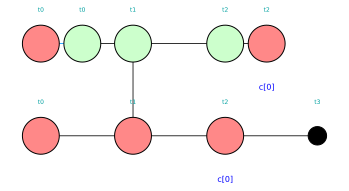

In [2]:
c = Circuit(2, bit_amount=1)
for gate in (HAD(0), CNOT(0, 1), Measurement(0, result_bit=0), ParityControlled('X', 1, ['c[0]'])):
    c.add_gate(gate)
m = QProgram(2, bits=1, initial_states={0: '0', 1: '0'})
m.add_circuit(c, name='measure and correct')
d = m.quantum_graph()
print("measurement results in the diagram:", sorted(boolean_variables(d)))
draw_graph(d, figsize=(6, 2.5))

The X-spider labelled `c[0]` at the end of qubit 0 is the measurement; the one on qubit 1 is the correction. Each run is the diagram with `c[0]` set to a value. In both runs the second qubit ends in $|0\rangle$: the correction undoes the random result.

c[0] = 0: the output state is proportional to [1.+0.j 0.+0.j]


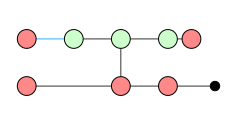

c[0] = 1: the output state is proportional to [1.+0.j 0.+0.j]


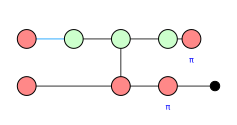

In [3]:
for value in (0, 1):
    run = d.substitute_variables({'c[0]': value})
    state = zx.tensorfy(run, preserve_scalar=False).ravel()
    print(f"c[0] = {value}: the output state is proportional to {np.round(state / state[np.argmax(abs(state))], 3)}")
    display(zx.draw_matplotlib(run, figsize=(4, 2)))

PyZX's own syntax for the correction, `if (c==1) x q[1];`, gives the same spider with phase $\pi\,c$ on qubit 1:

['HAD(0)', 'CNOT(0,1)', 'Measurement(0)', 'if(c==1) NOT(1)']


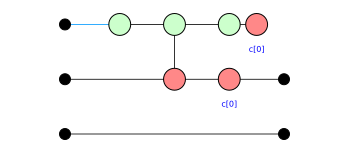

In [4]:
q = zx.Circuit.from_qasm('OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[2];\ncreg c[1];\n'
                         'h q[0];\ncx q[0],q[1];\nmeasure q[0] -> c[0];\nif (c==1) x q[1];\n')
print([str(g) for g in q.gates])
zx.draw_matplotlib(q.to_graph(), figsize=(6, 2.5))

## Part 2. T injection into the Steane code

The first program is the running example of the paper: a T gate is applied to a qubit protected by the Steane code (7 physical qubits, 1 logical qubit) by preparing a magic state in a second Steane block, entangling the two blocks and measuring the second one. Depending on the measurement results, a correction `S` is needed (here written as `S^dag` on every physical qubit, which is the logical `S`).

We group its seven stages into six blocks, as in the paper:

In [5]:
STEANE = [(0, 0, 'encode data', 'encoder'), (1, 2, 'prepare magic', 'state preparation'),
          (3, 3, 'check magic', 'syndrome extraction'), (4, 4, 'transversal CNOT', 'logical gate'),
          (5, 5, 'read out magic', 'logical measurement'), (6, 6, 'correct', 'correction')]

def compare_steane(**variant):
    """The program of the paper against a variant of it, block by block."""
    a, b = steane_t_injection(), steane_t_injection(**variant)
    return compare_programs(a, b, a.group_stages(STEANE), b.group_stages(STEANE))

original = steane_t_injection()
print(original.summary(original.group_stages(STEANE)).table())

block               role                 code before            code after             logical action                                    every run?  checks
0 encode data       encoder              [[1,1,1]]              [[7,1,3]]              I                                                 yes         ok
1 prepare magic     state preparation    [[7,1,3]]              [[7,1,3]] + [[7,1,3]]  I on qubits 0-6 (x) prepares T|+> on qubits 7-13  yes         ok
2 check magic       syndrome extraction  [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  I                                                 yes         ok
3 transversal CNOT  logical gate         [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  CNOT(0->1)                                        yes         ok
4 read out magic    logical measurement  [[7,1,3]] + [[7,1,3]]  [[7,1,3]]              I on qubits 0-6 (x) Z measurement on qubits 7-13  yes         ok
5 correct           correction           [[7,1,3]]              [[7,1,3]]           

The whole program, its six blocks shaded (time from left to right, one line per qubit: the data block 0–6, the magic block 7–13, the helpers 14–19):

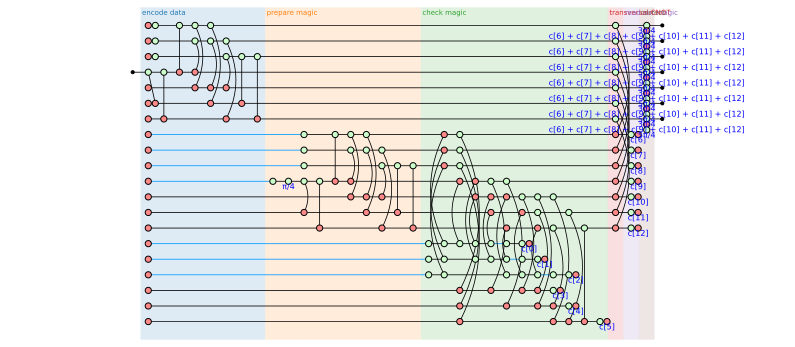

In [6]:
draw_program(original, level=original.group_stages(STEANE), show_time=False, labels=False, figsize=(14, 6))

### 2a. Measuring the checks in another order

The block *check magic* measures three X checks and then three Z checks. Suppose a compiler measures the Z checks first. The circuits are different, but the checks are stabilizers, which commute, so the order should not matter:

In [7]:
print(compare_steane(z_checks_first=True))

block               code before  code after  logical action  results checked
0 encode data       same         same        same            0 / 0
1 prepare magic     same         same        same            0 / 0
2 check magic       same         same        same            6 / 6
3 transversal CNOT  same         same        same            0 / 0
4 read out magic    same         same        same            7 / 7
5 correct           same         same        same            0 / 0
whole program       same         same        same
detectors: 9 and 9 independent, the same space
logically equivalent


The stage *check magic* of the two programs, on a time axis (the X checks are the CNOTs pointing from the helpers into the block, the Z checks the other way):

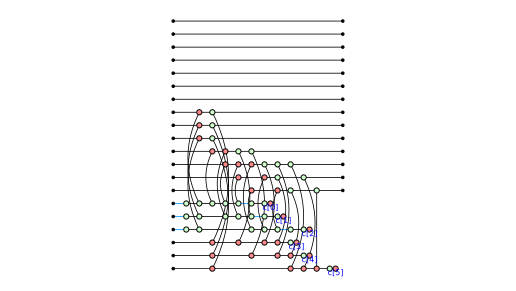

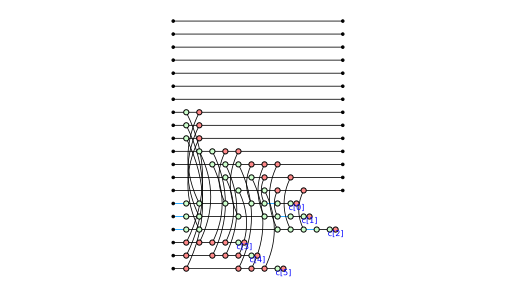

In [8]:
a, b = steane_t_injection(), steane_t_injection(z_checks_first=True)
display(draw_graph(a.stage_graph(3, classical=False), show_time=False, figsize=(9, 5)))
draw_graph(b.stage_graph(3, classical=False), show_time=False, figsize=(9, 5))

Every row is `same`, and the detectors are the same (9 independent ones, spanning the same space): **logically equivalent**, as expected.

### 2b. `S` instead of `S^dag` in the correction

Now the correction applies `S` instead of `S^dag` on every qubit. That looks like a bug, but it is not: `S = Z · S^dag`, so the result differs from the intended one only by a Pauli `Z` on the logical qubit, which can be tracked instead of applied (the *Pauli frame*).

In [9]:
print(compare_steane(correction='S'))

block               code before  code after  logical action  results checked
0 encode data       same         same        same            0 / 0
1 prepare magic     same         same        same            0 / 0
2 check magic       same         same        same            6 / 6
3 transversal CNOT  same         same        same            0 / 0
4 read out magic    same         same        same            7 / 7
5 correct           same         same        same            0 / 0
whole program       same         same        same
detectors: 9 and 9 independent, the same space
logically equivalent


The correction of the two programs (the last stage): each data qubit gets a rotation by $\mp\pi/2$, written as a spider and a phase gadget controlled by the parity of the readout:

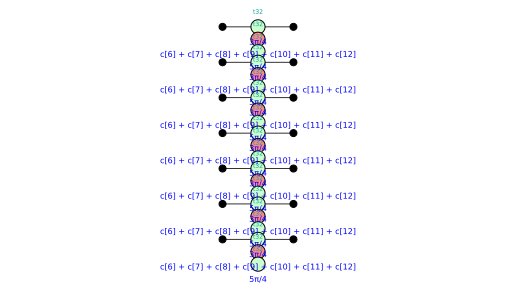

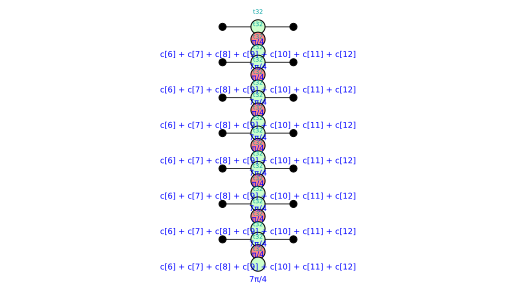

In [10]:
a, b = steane_t_injection(), steane_t_injection(correction='S')
display(draw_graph(a.stage_graph(6, classical=False), figsize=(9, 5)))
draw_graph(b.stage_graph(6, classical=False), figsize=(9, 5))

Again **logically equivalent**: the comparison of logical actions is *up to a Pauli frame*, exactly because such a difference does not need to be fixed.

### 2c. Leaving out the correction

Without the correction the program does `T` in some runs and `T^dag` in others. This is a real bug. The two programs then have different numbers of blocks, so we compare them one level up, where everything after the encoder is one block *inject T*:

In [11]:
a, b = steane_t_injection(), steane_t_injection(correct=False)
la = a.level_up(a.group_stages(STEANE), 1, 5, name='inject T', role='injection')
lb = b.level_up(b.group_stages(STEANE[:5]), 1, 4, name='inject T', role='injection')
print(compare_programs(a, b, la, lb))

block          code before  code after  logical action  results checked
0 encode data  same         same        same            0 / 0
1 inject T     same         same        DIFFERENT       13 / 13
whole program  same         same        DIFFERENT
detectors: 9 and 9 independent, the same space
NOT logically equivalent

first difference:
block 1: 'inject T' / 'inject T'  -- DIFFERENT
  code before     same
  code after      same
  logical action  DIFFERENT
  logical action: T in the first, T / T^dag in the second

whole programs  -- DIFFERENT
  code before     same
  code after      same
  logical action  DIFFERENT
  logical action: T in the first, T / T^dag in the second


The codes agree, and so do the checks (the same 13 results are checked, by the same 9 detectors), but the logical action does not: `T` in every run in the first program, `T` or `T^dag` depending on the run in the second. **Not equivalent**, and the report says which block and why.

### 2d. A check wired to the wrong qubit

Now the first Z check of *check magic* is wired to qubits 0, 3, 4, **6** instead of 0, 3, 4, **5** (one CNOT in the wrong place). That measures an operator that is not a stabilizer of the code, and changes the code:

In [12]:
print(compare_steane(first_z_check=(0, 3, 4, 6)))

block               code before  code after  logical action  results checked
0 encode data       same         same        same            0 / 0
1 prepare magic     same         same        same            0 / 0
2 check magic       same         DIFFERENT   not compared    6 / 5  <-
3 transversal CNOT  DIFFERENT    DIFFERENT   not compared    0 / 0
4 read out magic    DIFFERENT    DIFFERENT   not compared    7 / 7
5 correct           DIFFERENT    DIFFERENT   not compared    0 / 0
whole program       same         DIFFERENT   not compared
detectors: 9 and 8 independent, a different space
NOT logically equivalent

first difference:
block 2: 'check magic' / 'check magic'  -- DIFFERENT
  code before     same
  code after      DIFFERENT
  logical action  not compared
  code after: the first has IIIIIIIXIXXIIX and the second does not; the second has IIIIIIIZZIIIII, IIIIIIIIIZIZII, IIIIIIIIIIIIZZ and the first does not (qubits in the order [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13])
  logica

The stage *check magic* of the two programs. In the second, the last CNOT of the first Z check goes to qubit 6 instead of qubit 5:

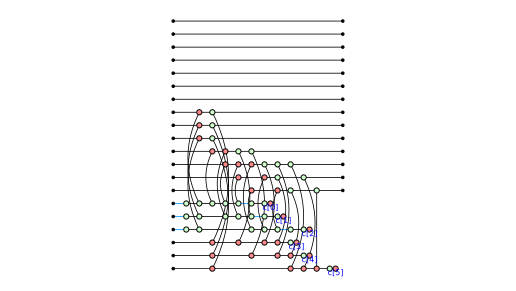

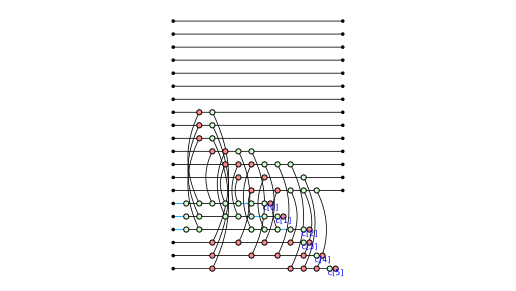

In [13]:
a, b = steane_t_injection(), steane_t_injection(first_z_check=(0, 3, 4, 6))
display(draw_graph(a.stage_graph(3, classical=False), show_time=False, figsize=(9, 5)))
draw_graph(b.stage_graph(3, classical=False), show_time=False, figsize=(9, 5))

The first difference is the **code after *check magic***: the report lists stabilizers that one program has and the other has not. Every later block then differs too, because it starts from a different code; that is a consequence, which is why the details are given for the first difference only. The detectors also differ (9 against 8), and in *check magic* one of the six check results is no longer checked (6 against 5). **Not equivalent.**

## Part 3. The fold-transversal Hadamard: a bug that only the checks reveal

The second program is the fold-transversal logical Hadamard on the distance-3 surface code. An earlier version of its circuit files contained a wiring error: in the round after the rotation, one Z check was wired to data qubit 2 instead of data qubit 4 (a single index in `ft_h_5.qasm`). We build both versions. The only difference is the line `cx q[4], q[14];` against `cx q[2], q[14];`.

In [14]:
N, BITS = 19, 35
X_ANC, Z_ANC = [10, 11, 12, 13], [14, 15, 16, 17]

def qasm(name):
    return open(os.path.join("circuits", "ft_h", name + ".qasm")).read()

def with_prefix(circ, gates):
    c = Circuit(N, bit_amount=BITS)
    for gate in gates:
        c.add_gate(gate)
    c.add_circuit(circ)
    return c

def fold_h(miswired=False):
    """The fold-transversal Hadamard program; ``miswired`` puts back the wiring error."""
    ft_h_5 = qasm("ft_h_5")
    if miswired:
        ft_h_5 = ft_h_5.replace("cx q[4], q[14];", "cx q[2], q[14];", 1)
    load = lambda text: zx.Circuit.from_qasm(text)
    p = QProgram(N, bits=BITS, initial_states={**{q: '0' for q in range(1, 10)}, 18: '0',
                                               **{a: '+' for a in X_ANC + Z_ANC}})
    p.add_circuit(load(qasm("ft_h")), name="encode + X checks")
    p.add_circuit(load(qasm("ft_h_2")), name="transversal H")
    p.add_circuit(with_prefix(load(qasm("ft_h_3")), [Reset(a) for a in X_ANC]), name="Z checks (code 2)")
    p.add_circuit(load(qasm("ft_h_3.2")), name="X checks (code 2)")
    p.add_permutation([0, 3, 6, 9, 2, 5, 8, 1, 4, 7] + list(range(10, 19)), name="rotate 90")
    p.add_circuit(with_prefix(load(ft_h_5), [Reset(a) for a in Z_ANC]), name="Z checks", physical=True)
    p.add_circuit(with_prefix(load(qasm("ft_h_5.2")), [g for a in X_ANC for g in (Reset(a), HAD(a))]),
                  name="X checks", physical=True)
    p.add_circuit(with_prefix(load(qasm("ft_h_6")), [Reset(a) for a in Z_ANC]), name="Z checks + decode",
                  physical=True)
    return p

FOLD = [(0, 0, 'encode + round 1', 'encoder'), (1, 1, 'transversal H', 'logical gate'),
        (2, 3, 'round in code 2', 'syndrome extraction'), (4, 4, 'rotate', 'logical gate'),
        (5, 6, 'round in code 1', 'syndrome extraction'), (7, 7, 'checks + decode', 'decoder')]

correct, broken = fold_h(), fold_h(miswired=True)
print(compare_programs(correct, broken, correct.group_stages(FOLD), broken.group_stages(FOLD)))

block               code before  code after  logical action  results checked
0 encode + round 1  same         same        same            4 / 4
1 transversal H     same         same        same            0 / 0
2 round in code 2   same         same        same            8 / 8
3 rotate            same         same        same            0 / 0
4 round in code 1   same         same        same            8 / 7  <-
5 checks + decode   same         same        same            13 / 13
whole program       same         same        same
detectors: 24 and 22 independent, a different space
NOT logically equivalent


The stage with the wrong check, one time step at a time on the grid of the 19 qubits (`draw_program_slices`): first the correct program, then the broken one. In the broken one, one CNOT reaches across the grid to data qubit 2 instead of a neighbour; the broken stage also takes two more time steps.

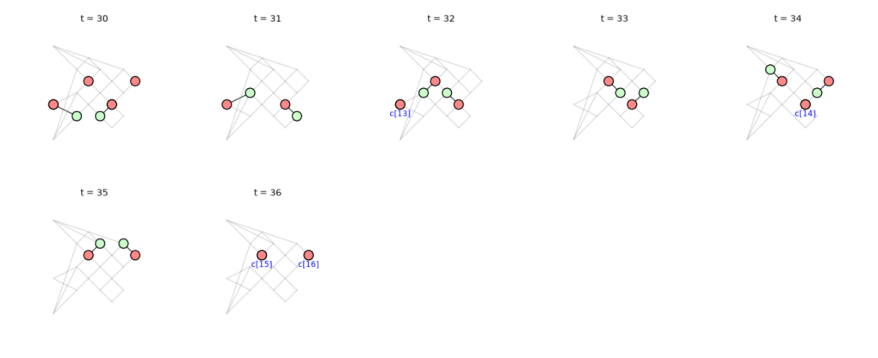

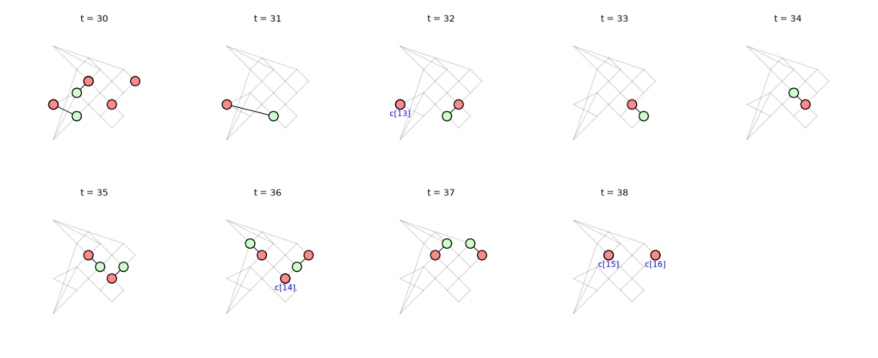

In [15]:
correct.topology = broken.topology = build_topology()
display(draw_program_slices(correct, stage=5, cols=5, panel=(2.4, 2.4)))
draw_program_slices(broken, stage=5, cols=5, panel=(2.4, 2.4))

This one is subtle. **Every code and every logical action agree**: the wrong check measures `Z1 Z2`, which is not a stabilizer, but the X checks measured right after it, in the same round, restore the code, and the logical Hadamard still comes out. A comparison of the logical operations alone would call the two programs equal.

What differs is the checking: the broken program has **22 independent detectors instead of 24**, and the last column shows where they went: in *round in code 1*, the block with the wrong check, 8 results are checked in the correct program and 7 in the broken one. Two results of that block are involved:

* `c[13]`, the result of the wrong check (helper qubit `q[14]`);
* `c[18]`, the result of the X check `X2 X3` in the same round (helper qubit `q[10]`), which does not commute with `Z1 Z2`.

In [16]:
level = lambda p: p.group_stages(FOLD)
for name, p in (("correct", correct), ("broken", broken)):
    report = p.summary(level(p)).blocks[4].measurements
    print(name)
    for result in ('c[13]', 'c[18]'):
        m = report.measurements[result]
        print("   ", m, "  detectors:", [str(d) for d in m.relations])

correct
    c[13] (stage 5, qubit 14): tied by c[13] + c[3] = 0   detectors: ['c[13] + c[3]']
    c[18] (stage 6, qubit 10): always 0   detectors: ['c[18]']


broken
    c[13] (stage 5, qubit 14): gauge: random, affects nothing   detectors: []
    c[18] (stage 6, qubit 10): in the Pauli frame   detectors: ['c[28] + c[18] + c[27]']


In the correct program `c[13]` measures `Z1 Z4` and is compared with `c[3]`, the check `X7 X8` of the first round, which the transversal H and the rotation (7 to 1, 8 to 4) turn into `Z1 Z4`; and `c[18]` is always 0. In the broken program `c[13]` is random and no detector mentions it, and `c[18]` is random too; it is still compared with the final X readout of qubits 2 and 3 (`c[27]`, `c[28]`), so it counts as checked, but its value is no longer known in advance. That is two independent detectors fewer: less information for a decoder, and nothing in the logical operation shows it. This is why the comparison asks for the same detectors, not only the same codes and operations.

A check with every measurement result set to 0 cannot find this: a check of one run cannot tell which results are random and which are checked, and the logical operation, which it does see, is right in the broken circuit too.

## Part 4. What `compare_programs` does inside

For each program, `compare_programs` asks the program's `summary` for every block: the **code before** and **after** it, and its **logical action**; it also reduces each whole program once to get its **detectors**. Then it compares the two answers row by row. Each answer comes from a ZX-diagram rewritten into the *generalized parity form*: one Z-spider per input, one X-spider per output, and the outcome-dependent phases kept on the spiders.

Here is that on one block of the T-injection program, the *transversal CNOT*. First the block, cut out of the program:

block 3: transversal CNOT - stages (4,)


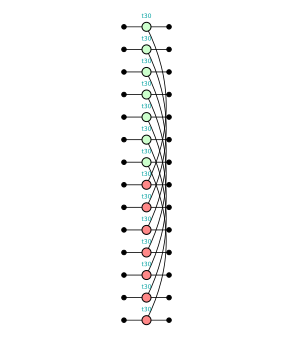

In [17]:
level = original.group_stages(STEANE)
blk = original.block(level, 3)
block = original.block_graph(level, 3, classical=False)
print("block 3:", blk, "- stages", blk.stages)
draw_graph(block, figsize=(5, 6))

The codes before and after it, read off the program up to that point (`code_at`):

In [18]:
code_in, code_out = original.code_at(blk.stages[0] - 1), original.code_at(blk.stages[-1])
print("code before the block:", code_in.data())
print("code after the block: ", code_out.data())

code before the block: [[7, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6
    stabilizer +XXXIXII
    stabilizer +XXIIIXX
    stabilizer +XIXXIIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII
[[7, 1, 3]] CSS code on qubits 7, 8, 9, 10, 11, 12, 13 (holding a non-Clifford logical state)
    stabilizer +XXXIXII
    stabilizer +XXIIIXX
    stabilizer +XIXXIIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII
code after the block:  [[7, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6 (holding a non-Clifford logical state)
    stabilizer +XXXIXII
    stabilizer +XXIIIXX
    stabilizer +XIXXIIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII
[[7, 1, 3]] CSS code on qubits 7, 8, 9, 10, 11, 12, 13 (holding a non-Clifford logical state)
    stabilizer +XXXIXII
    stabilizer +XXIIIXX
    stabilizer +XIX

The logical action is the block between the **ideal encoder** of the code before it and the **ideal decoder** of the code after it: what the block does to the protected qubits, with the physical qubits taken away. `logical_action` builds that diagram and reduces it. Below, the diagram after each step of the reduction (`to_gpf_steps`). These diagrams have no natural coordinates, so they are drawn where a spring energy is lowest (`draw_relaxed`): only the connections matter.

the diagram (58 spiders)


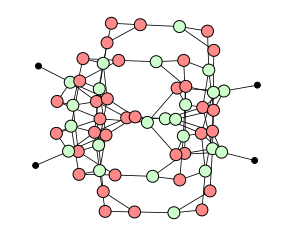

identity spiders removed, neighbours of the same colour fused (36 spiders)


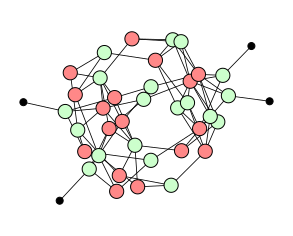

Hadamard edges pushed to the boundary wires, spiders fused (36 spiders)


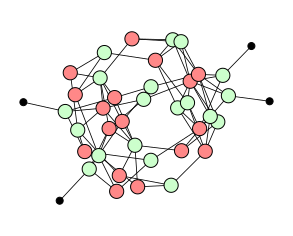

phases that are not Pauli moved onto gadgets (36 spiders)


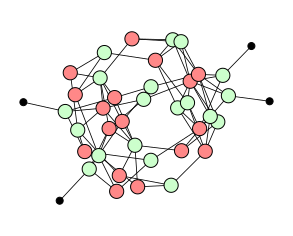

the bialgebra rule applied until two layers remain (4 spiders)


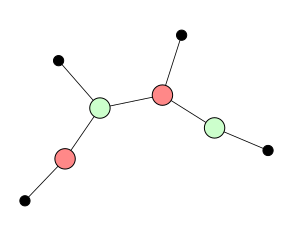

one Z-spider per input and one X-spider per output: the normal form (4 spiders)


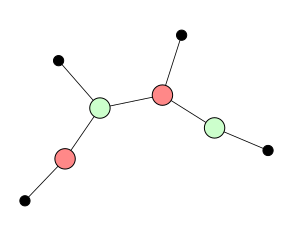

In [19]:
act = logical_action(block, code_in.data(), code_out.data())
for what, h in to_gpf_steps(act.composite):
    spiders = sum(1 for v in h.vertices() if h.type(v) != 0)
    print(f"{what} ({spiders} spiders)")
    display(draw_relaxed(h, figsize=(5, 4)))

The diagram shrinks from 58 spiders to 4. The two middle steps leave the number of spiders as it is (there is no T gate in this block, so no phase becomes a gadget). The row reduction then leaves the normal form, drawn as a normal form (Z-spiders on the left, X-spiders on the right). It is a **CNOT on the two logical qubits**:

verdict: deterministic: every run implements CNOT(0->1)


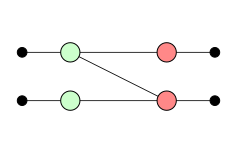

In [20]:
print("verdict:", act.verdict())
zx.draw_matplotlib(act.graph, figsize=(4, 2.5))

`compare_programs` does this for every block of both programs (and for the prefixes that give the codes), and compares the results: the codes as stabilizer groups, the logical actions run by run up to a Pauli, the detectors as spaces of parities.

## Part 5. How long it takes, and why

Every step above is a rewrite of a ZX-diagram, and the rewrites are cheap. For a program whose diagram has $n$ spiders:

* cutting a block or a prefix out of the program is linear in $n$;
* the normal form (spider fusion, pushing Hadamards to the boundary, the bialgebra rule) is polynomial: every application of the bialgebra rule lowers a count of spiders fixed at the start;
* the row reduction is Gaussian elimination over GF(2), at most cubic in $n$ per round, with a cap on the number of rounds.

The programs here are not Clifford, but that does not make them expensive: a T gate is not expanded into a sum of Clifford terms, as a simulation would have to do (whose cost doubles with every T gate in general); it becomes a phase gadget that the rewrites carry along.

Three parts are exponential, each in a number that is small in these programs: **presenting a code** (choosing the lightest generators and logical operators enumerates combinations of generators; it is the most expensive step here), the **gadget test** (in the number of independent gadget parities, one or two here), and the **classes of runs** of a logical action (one per assignment of the results left in the reduced block). The times of the comparisons above, on this machine:

In [21]:
for name, variant in [('Z checks first', dict(z_checks_first=True)), ('S instead of S^dag', dict(correction='S')),
                      ('a check on the wrong qubit', dict(first_z_check=(0, 3, 4, 6)))]:
    t0 = time.perf_counter()
    compare_steane(**variant)
    print(f"Steane injection, {name:28} {time.perf_counter() - t0:5.1f} s")
t0 = time.perf_counter()
compare_programs(correct, broken, correct.group_stages(FOLD), broken.group_stages(FOLD))
print(f"fold-transversal H, mis-wired against correct {time.perf_counter() - t0:5.1f} s")

Steane injection, Z checks first                 3.5 s


Steane injection, S instead of S^dag             3.5 s


Steane injection, a check on the wrong qubit     3.7 s


fold-transversal H, mis-wired against correct   0.7 s


## Summary

| programs compared | verdict | why |
|---|---|---|
| Steane injection, Z checks measured first | equivalent | same codes, operations and detectors |
| Steane injection, `S` instead of `S^dag` | equivalent | the operations differ by a Pauli frame only |
| Steane injection, no correction | not equivalent | *inject T* is `T` against `T` / `T^dag` |
| Steane injection, a check on the wrong qubit | not equivalent | the code after *check magic* differs; one detector fewer |
| fold-transversal H, mis-wired against corrected | not equivalent | same codes and operations, two detectors fewer, lost in *round in code 1* |

### What the comparison does not do

* it is not a proof that two circuits are equal as circuits; it compares codes, logical operations up to a Pauli frame, and detectors;
* the two levels must have the same number of blocks, paired in order;
* logical operations are compared only where the codes around a block agree by program qubit, because the logical basis is read from the code;
* if the two programs name their measurement results differently, only the *numbers* of independent detectors are compared, not the detectors themselves;
* when a Clifford gate is applied only in some runs (controlled by a measurement result), the code after it differs between runs and the tool cannot read it; such blocks are not compared, so for such programs the verdict is at best *not decided*.